# Synthetic graph detection and event tracking

Generate a new run with `python -m reddit_sna synthetic-week1 --config configs/detection_development.toml --run-id week1-synthetic-demo` first. This notebook reads verified saved outputs; it does not tune thresholds or rerun the detector. The recipes were already inspected, so these are descriptive synthetic results, not a new unseen experiment. See `docs/RUNBOOK.md` and `reports/WEEK1_REPORT.md`.

For another run, set `REDDIT_SYNTHETIC_REFERENCE` to its `pair-reference.json`. Legacy T02 replay remains possible with `configs/legacy-handoff-reference.json` plus explicit bundle and tracking paths. No cached output is committed in this source notebook.

## Environment and package APIs

In [1]:
import os
import sys
import json
from pathlib import Path
from datetime import datetime, timezone
from IPython.display import display, HTML, JSON
import matplotlib.pyplot as plt
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
ROOT = Path(os.environ.get("REDDIT_SNA_PROJECT", Path.cwd())).resolve()
if "REDDIT_SNA_PROJECT" not in os.environ:
    ROOT = next((p for p in [ROOT, *ROOT.parents] if (p / "pyproject.toml").is_file()), ROOT)
if not (ROOT / "pyproject.toml").is_file():
    raise ValueError("Set REDDIT_SNA_PROJECT to the repository root")
print("Active interpreter:", sys.executable)
print("Repository:", ROOT)

from reddit_sna.reporting.synthetic_demo import load_synthetic_demo, build_synthetic_figures, export_synthetic_demo, table_html
from reddit_sna.reporting.synthetic_cases import analyze_synthetic_cases, case_summary, build_case_figures, export_case_analysis
from reddit_sna.reporting.tracking_demo import load_tracking_demo, build_tracking_figures, export_tracking_demo

Active interpreter: <PROJECT_ROOT>\.venv\Scripts\python.exe
Repository: <PROJECT_ROOT>


## Explicit input reference and fresh output paths

In [2]:
REFERENCE = Path(os.environ.get("REDDIT_SYNTHETIC_REFERENCE", ROOT / "artifacts/detection-tracking/week1-synthetic-demo/pair-reference.json")).resolve()
reference = json.loads(REFERENCE.read_text(encoding="utf-8"))
BUNDLE = Path(os.environ.get("REDDIT_SYNTHETIC_BUNDLE", reference.get("bundle", ROOT / "artifacts/handoff/phuc-dang-week1-20261019-001"))).resolve()
DATASET = os.environ.get("REDDIT_SYNTHETIC_DEMO_DATASET", "dev-grow-easy-g11")
STAMP = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
OUTPUT = Path(os.environ.get("REDDIT_SYNTHETIC_DEMO_OUTPUT", ROOT / "artifacts/detection-tracking" / f"synthetic-notebook-{STAMP}")).resolve()
ANALYSIS_OUTPUT = OUTPUT.with_name(OUTPUT.name + "-cases")
TRACKING_OUTPUT = OUTPUT.with_name(OUTPUT.name + "-tracking")
NOTEBOOK_SOURCE = ROOT / "notebooks/detection_tracking/01_synthetic_demo.ipynb"
for destination in (OUTPUT, ANALYSIS_OUTPUT, TRACKING_OUTPUT):
    if destination.exists() or not destination.is_relative_to(ROOT / "artifacts") or destination.is_relative_to(BUNDLE) or BUNDLE.is_relative_to(destination):
        raise ValueError("Choose a new output inside artifacts, separate from inputs")
OUTPUT.parent.mkdir(parents=True, exist_ok=True)
print("Bundle:", BUNDLE)
print("Interpretation:", reference.get("interpretation", "Historical fixed T02 replay; original chronology is not recertified"))

Bundle: <PROJECT_ROOT>\artifacts\detection-tracking\week1-group-synthetic-001\bundle
Interpretation: Current descriptive rerun of inspected recipes, not a new unseen test


## Verify all source runs before reading scores

In [3]:
demo = load_synthetic_demo(BUNDLE, expected_delivery_sha256=reference["delivery_manifest_sha256"], dataset_id=DATASET)
display(HTML(table_html([dict(split=s, **i["counts"], source_manifest_sha256=i["source_manifest_sha256"]) for s,i in demo["inventories"].items()])))
display(JSON(demo["recipes"]["development"]))

split,datasets,snapshots,snapshot_detector_runs,source_manifest_sha256
development,18,36,108,9ecc38c6bf3b4bd0aeb0a1a88b3a188d1df5c1d77060996667fc9609836c3820
evaluation,18,36,108,aa46bf2eeafc286a6e9433d87adb5d23f343f1c03c3e0b75d9facc26d6d4407a


<IPython.core.display.JSON object>

## Detection quality, coverage and undefined AMI

In [4]:
summary = [r for r in demo["summary_view"] if r["level"] == "all_scenarios"]
display(HTML(table_html(summary)))
print("Missing AMI is retained with its reason; coverage 1.0 does not imply correct partitions.")

split,level,scenario,detector_seed,seed_role,n_rows,n_ami_valid,n_ami_missing,ami_mean,coverage_mean,missing_reasons
development,all_scenarios,—,0,canonical,36,33,3,0.955880,1.000000,"{""truth_constant"":3}"
development,all_scenarios,—,1,diagnostic,36,33,3,0.948748,1.000000,"{""truth_constant"":3}"
development,all_scenarios,—,2,diagnostic,36,33,3,0.954641,1.000000,"{""truth_constant"":3}"
evaluation,all_scenarios,—,0,canonical,36,33,3,0.933117,1.000000,"{""truth_constant"":3}"
evaluation,all_scenarios,—,1,diagnostic,36,33,3,0.948420,1.000000,"{""truth_constant"":3}"
evaluation,all_scenarios,—,2,diagnostic,36,33,3,0.940472,1.000000,"{""truth_constant"":3}"


Missing AMI is retained with its reason; coverage 1.0 does not imply correct partitions.


## Full selected networks: display does not determine metrics

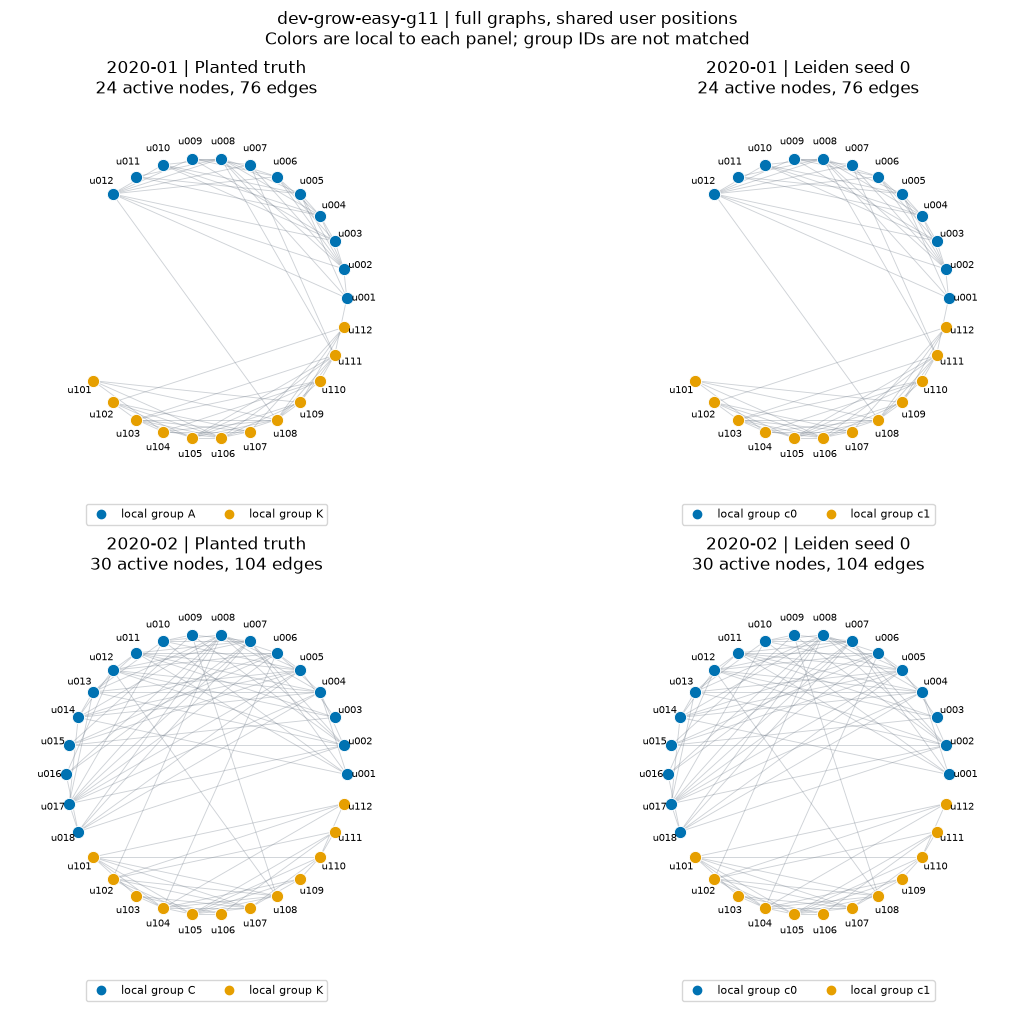

dataset_id,identity_scope,split,scenario,difficulty,generator_seed,month,detector_seed,gamma,canonical,truth_reference,detector_reference,active_nodes,endpoint_nodes,assigned_nodes,isolated_nodes,coverage,coverage_status,true_communities_all_nodes,true_communities_scored_nodes,predicted_communities,n_scored_users,ami,ami_status,ami_reason,ami_policy_id,ami_average_method,sklearn_version
dev-grow-easy-g11,dev-grow-easy-g11,development,grow,easy,11,2020-01,0,1.0,True,truth-dev-grow-easy-g11,dev-grow-easy-g11:synthetic-planted-undirected-v1:b7482417aac29cf74606f5ef9b262f1448ef62ff0eb7f300a856bdb16faaf26c:leiden-rb-v2-gamma1-seed0,24,24,24,0,1.0,defined,2,2,2,24,1.0,ok,—,synthetic-ami-v1,arithmetic,1.9.1
dev-grow-easy-g11,dev-grow-easy-g11,development,grow,easy,11,2020-02,0,1.0,True,truth-dev-grow-easy-g11,dev-grow-easy-g11:synthetic-planted-undirected-v1:b7482417aac29cf74606f5ef9b262f1448ef62ff0eb7f300a856bdb16faaf26c:leiden-rb-v2-gamma1-seed0,30,30,30,0,1.0,defined,2,2,2,30,1.0,ok,—,synthetic-ami-v1,arithmetic,1.9.1


In [5]:
figures = build_synthetic_figures(demo)
for figure in figures.values():
    plt.close(figure)
display(figures["01_network"])
display(HTML(table_html([s["metric"] for s in demo["network"]["snapshots"]])))

## Canonical quality and diagnostic seed variation

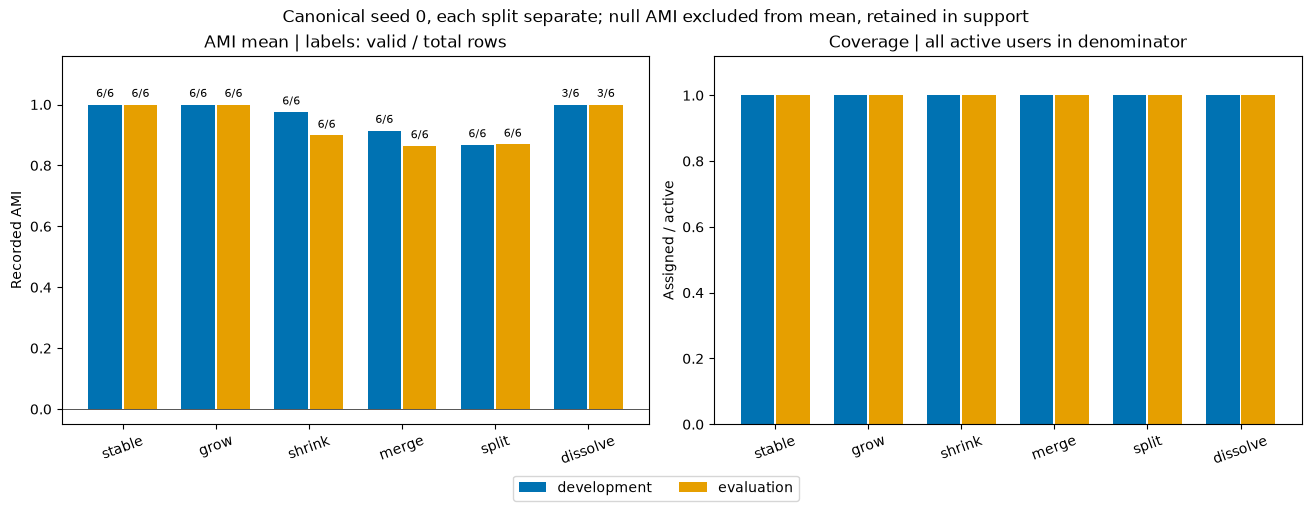

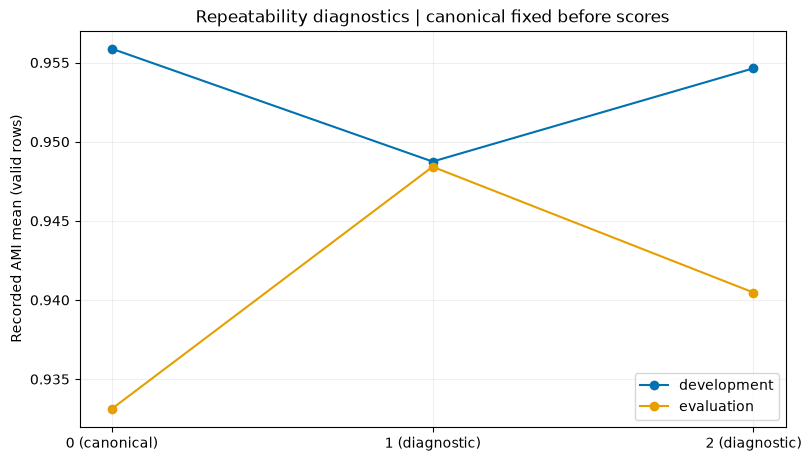

Seed 0 remains canonical; diagnostic seeds are not independent test datasets.


In [6]:
display(figures["02_quality"])
display(figures["03_seeds"])
print("Seed 0 remains canonical; diagnostic seeds are not independent test datasets.")

## Recorded stage timing

split,phase,wall_seconds,scope
development,generation,1.699473,wrapper wall time including dataset checkpoints and end-of-stage integrity checks; excludes boundary checkpoint writes
development,detection,4.200614,wrapper wall time including dataset checkpoints and end-of-stage integrity checks; excludes boundary checkpoint writes
development,evaluation,4.766377,wrapper wall time including dataset checkpoints and end-of-stage integrity checks; excludes boundary checkpoint writes
development,run_total,12.114539,from recorder initialization through final verification; excludes final manifest publication
evaluation,generation,1.979133,wrapper wall time including dataset checkpoints and end-of-stage integrity checks; excludes boundary checkpoint writes
evaluation,detection,4.941338,wrapper wall time including dataset checkpoints and end-of-stage integrity checks; excludes boundary checkpoint writes
evaluation,evaluation,5.618520,wrapper wall time including dataset checkpoints and end-of-stage integrity checks; excludes boundary checkpoint writes
evaluation,run_total,15.430631,from recorder initialization through final verification; excludes final manifest publication


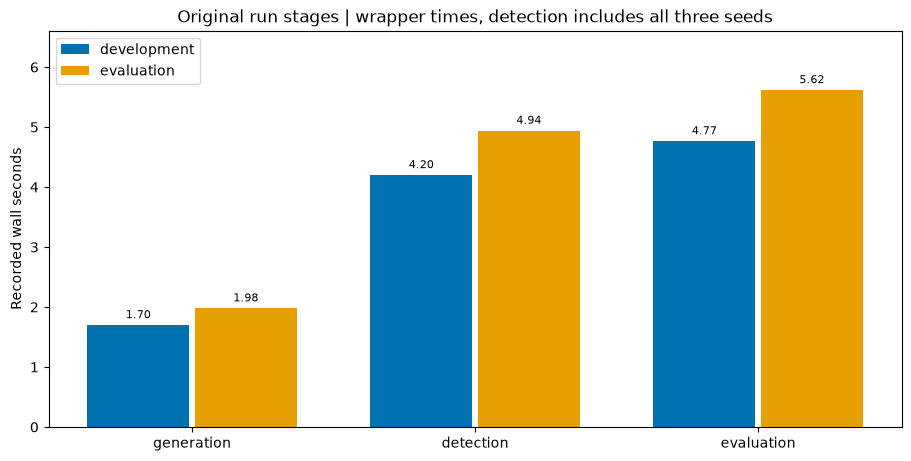

Peak native memory was not measured; no zero value is invented.


In [7]:
display(HTML(table_html(demo["timings"])))
display(figures["04_timing"])
print("Peak native memory was not measured; no zero value is invented.")

## Post-hoc difficult and undefined-score cases

kind,split,dataset_id,month,detector_seed,ami,ami_status,ami_reason,coverage,active_nodes,edges,assigned_nodes,unassigned_nodes,truth_groups,predicted_groups,scored_pairs,truth_same_pred_different_pairs,truth_different_pred_same_pairs,selection,tied_minimum_rows
hard,development,dev-merge-easy-g11,2020-02,0,0.724165,ok,—,1.000000,36,185,36,0,2,3,630,144,0,"lowest recorded non-null canonical AMI, then dataset_id/month within split",2
null,development,dev-dissolve-easy-g11,2020-02,0,—,degenerate_partition,truth_constant,1.000000,12,25,12,0,1,3,66,47,0,first recorded canonical null by dataset_id/month within split,—


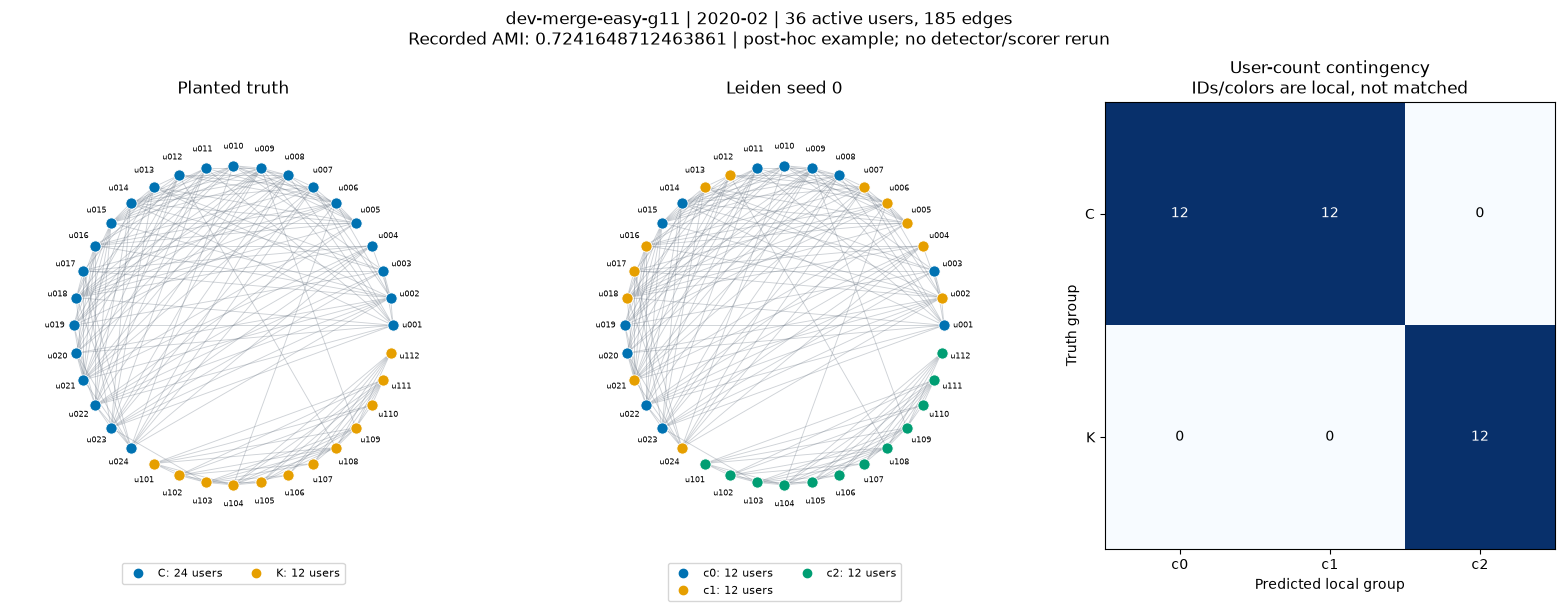

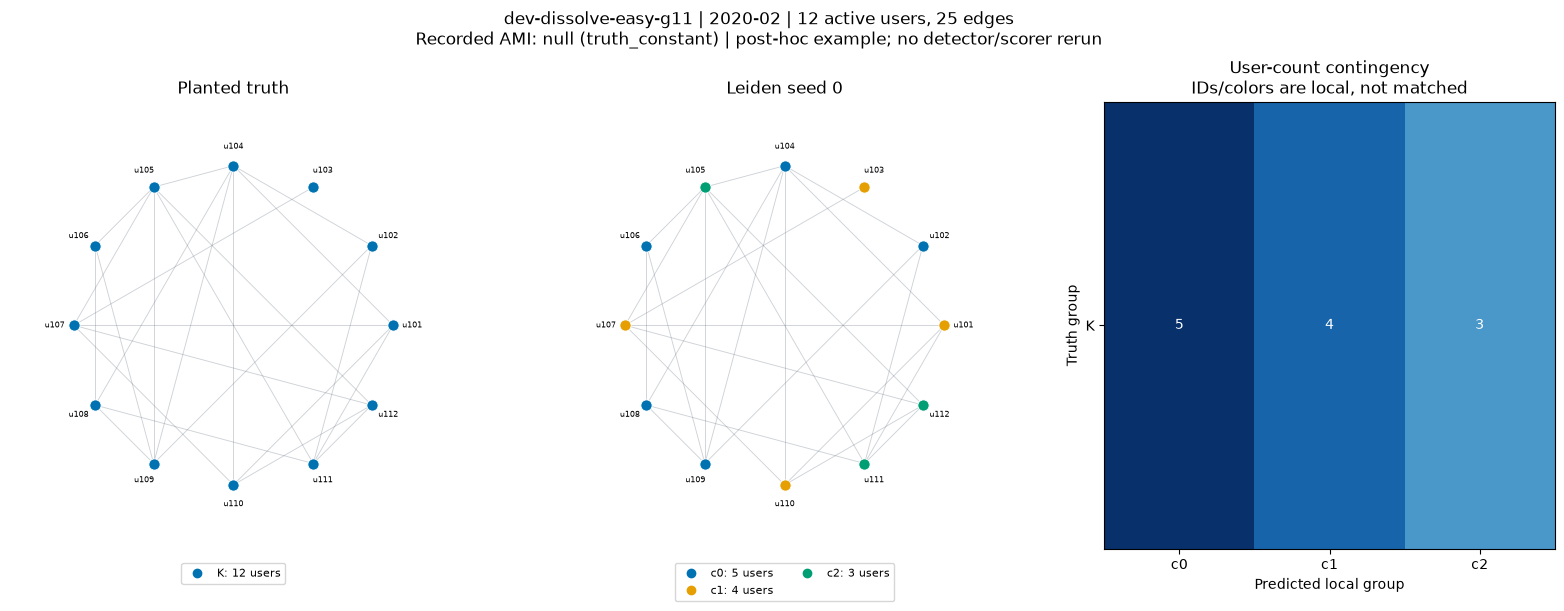

In [8]:
cases = analyze_synthetic_cases(demo, split="development")
display(HTML(table_html(case_summary(cases))))
case_figures = build_case_figures(cases)
for figure in case_figures.values():
    plt.close(figure)
    display(figure)

## Explain the errors with retained graph evidence

In [9]:
for case in cases:
    details = case["description"]
    print(case["dataset_id"], case["month"], "truth groups:", details["truth_groups"], "detected groups:", details["predicted_groups"])
    display(HTML(table_html(details["edge_blocks"])))
    display(JSON(case["inputs"]))
print("These selected examples are explanatory diagnostics, not a causal proof or parameter selection rule.")

dev-merge-easy-g11 2020-02 truth groups: 2 detected groups: 3


predicted_group_a,predicted_group_b,users_a,users_b,edges,possible_edges,density
c0,c0,12,12,46,66,0.696970
c0,c1,12,12,52,144,0.361111
c0,c2,12,12,2,144,0.013889
c1,c1,12,12,42,66,0.636364
c1,c2,12,12,2,144,0.013889
c2,c2,12,12,41,66,0.621212


<IPython.core.display.JSON object>

dev-dissolve-easy-g11 2020-02 truth groups: 1 detected groups: 3


predicted_group_a,predicted_group_b,users_a,users_b,edges,possible_edges,density
c0,c0,5,5,7,10,0.700000
c0,c1,5,4,2,20,0.100000
c0,c2,5,3,5,15,0.333333
c1,c1,4,4,4,6,0.666667
c1,c2,4,3,4,12,0.333333
c2,c2,3,3,3,3,1.000000


<IPython.core.display.JSON object>

These selected examples are explanatory diagnostics, not a causal proof or parameter selection rule.


## Export detection and case analysis with provenance

In [10]:
metadata = export_synthetic_demo(demo, figures, OUTPUT, notebook=NOTEBOOK_SOURCE)
analysis_metadata = export_case_analysis(demo, cases, case_figures, ANALYSIS_OUTPUT, notebook=NOTEBOOK_SOURCE)
print("Detection export:", OUTPUT, metadata["status"])
print("Case export:", ANALYSIS_OUTPUT, analysis_metadata["status"])

Detection export: <PROJECT_ROOT>\artifacts\detection-tracking\synthetic-notebook-20261021T133831579772Z complete
Case export: <PROJECT_ROOT>\artifacts\detection-tracking\synthetic-notebook-20261021T133831579772Z-cases complete


## Truth tracking versus detector-plus-tracking

In [11]:
legacy_pair = ROOT / "artifacts/detection-tracking/phuc-dang-final-20261020-001"
paths = reference.get("tracking", {})
TRACKING_DEVELOPMENT = Path(os.environ.get("REDDIT_TRACKING_DEVELOPMENT", paths.get("development", legacy_pair / "development"))).resolve()
TRACKING_EVALUATION = Path(os.environ.get("REDDIT_TRACKING_EVALUATION", paths.get("evaluation", legacy_pair / "evaluation"))).resolve()
tracking = load_tracking_demo(TRACKING_DEVELOPMENT, TRACKING_EVALUATION, input_pins=reference.get("source_manifest_sha256"))
display(HTML(table_html(tracking["summary"])))
print("Mean dataset F1 and pooled F1 are different summaries. Preserve unmatched truth and extra detector groups.")

split,route,support,mean_dataset_macro_f1,pooled_macro_f1,correct,matched_coverage,extra_detector
development,truth_tracking,39,0.305556,1.000000,39,1.000000,0
development,detector_tracking,39,0.256173,0.850000,33,1.000000,3
evaluation,truth_tracking,39,0.305556,1.000000,39,1.000000,0
evaluation,detector_tracking,39,0.217593,0.655143,28,1.000000,6


Mean dataset F1 and pooled F1 are different summaries. Preserve unmatched truth and extra detector groups.


## Confusion matrices retain all six events

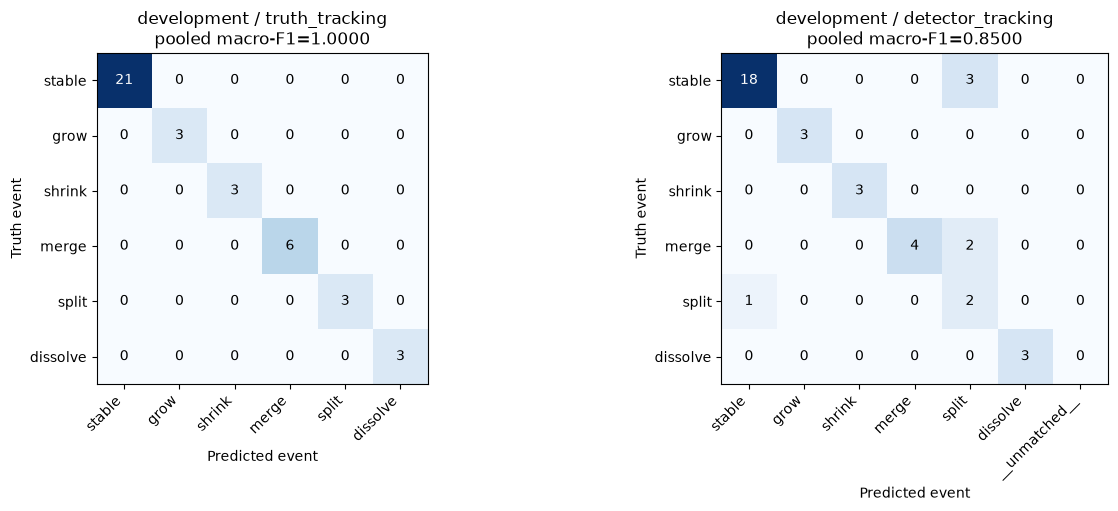

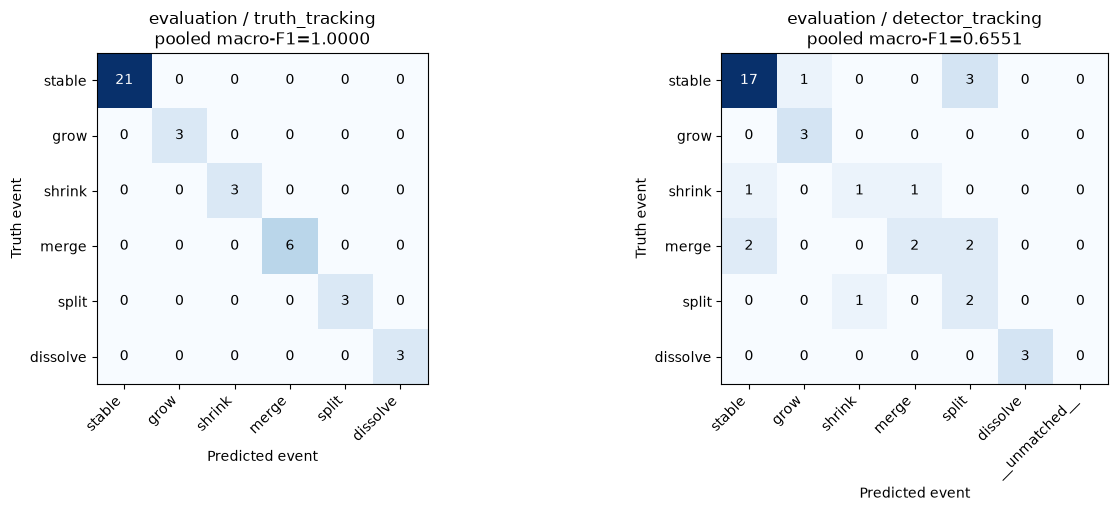

In [12]:
tracking_figures = build_tracking_figures(tracking)
for figure in tracking_figures.values():
    plt.close(figure)
    display(figure)

## Per-class metrics and actual failures

In [13]:
display(HTML(table_html(tracking["per_class"])))
display(HTML(table_html(tracking["errors"], ["split", "dataset_id", "source_community_id", "truth_event", "predicted_event"])))
print("Source mapping is an evaluator operation; truth does not influence the tracker.")

split,route,event,precision,recall,f1,support
development,truth_tracking,stable,1.000000,1.000000,1.000000,21
development,truth_tracking,grow,1.000000,1.000000,1.000000,3
development,truth_tracking,shrink,1.000000,1.000000,1.000000,3
development,truth_tracking,merge,1.000000,1.000000,1.000000,6
development,truth_tracking,split,1.000000,1.000000,1.000000,3
development,truth_tracking,dissolve,1.000000,1.000000,1.000000,3
development,detector_tracking,stable,0.947368,0.857143,0.900000,21
development,detector_tracking,grow,1.000000,1.000000,1.000000,3
development,detector_tracking,shrink,1.000000,1.000000,1.000000,3
development,detector_tracking,merge,1.000000,0.666667,0.800000,6


split,dataset_id,source_community_id,truth_event,predicted_event
development,dev-dissolve-easy-g11,K,stable,split
development,dev-dissolve-easy-g12,K,stable,split
development,dev-dissolve-easy-g13,K,stable,split
development,dev-merge-easy-g11,A,merge,split
development,dev-merge-easy-g11,B,merge,split
development,dev-split-easy-g13,A,split,stable
evaluation,eval-dissolve-easy-g101,K,stable,split
evaluation,eval-dissolve-easy-g102,K,stable,split
evaluation,eval-dissolve-easy-g103,K,stable,split
evaluation,eval-merge-easy-g101,B,merge,split


Source mapping is an evaluator operation; truth does not influence the tracker.


## Save tracking results and state the limits

In [14]:
tracking_metadata = export_tracking_demo(tracking, tracking_figures, TRACKING_OUTPUT)
print("Tracking export:", TRACKING_OUTPUT)
display(JSON(tracking_metadata))
print("Synthetic benchmark only. Historical partner acceptance, original Dang freeze, unseen scientific evaluation and paper novelty are not certified by this notebook.")

Tracking export: <PROJECT_ROOT>\artifacts\detection-tracking\synthetic-notebook-20261021T133831579772Z-tracking


<IPython.core.display.JSON object>

Synthetic benchmark only. Historical partner acceptance, original Dang freeze, unseen scientific evaluation and paper novelty are not certified by this notebook.
